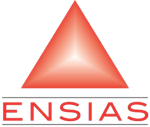

# TP 1 — Introduction au machine learning

**Module :** Introduction au Machine Learning
**Enseignant :** Prof. Aissam BERRAHOU — ENSIAS, Université Mohammed V de Rabat
**Niveau :** 2e année cycle ingénieur
**Durée estimée :** 2 heures
**Support associé :** Lecture 1 — Introduction au machine learning

## 1. Objectifs pédagogiques

*Ce TP prolonge le cours : vous allez refaire sur machine les calculs vus en séance, puis passer à un vrai jeu de données.*

1. Prendre en main **NumPy**, **pandas** et **Matplotlib**.
2. Coder une première **boucle d'apprentissage** : le modèle $\hat y = w \times x$ des slides.
3. Explorer un jeu de données réel (Iris) : tableau, statistiques, graphiques.
4. Entraîner un premier modèle **supervisé** (KNN) et un premier **clustering** (K-means).
5. Comprendre la séparation **apprentissage / test**.

## 2. Rappel théorique

*Avant de coder, un rapide rappel des formules dont nous aurons besoin.*

Les 4 ingrédients d'un algorithme d'apprentissage :
1. des **données** $(x_i, y_i)$ ;
2. un **modèle** avec des paramètres, ici $\hat y = w\,x$ ;
3. une **fonction coût**, ici $L(w) = \frac{1}{n}\sum_i (w x_i - y_i)^2$ ;
4. un **algorithme d'optimisation**, ici la descente de gradient : $w \leftarrow w - \alpha \frac{dL}{dw}$, avec $\frac{dL}{dw} = \frac{2}{n}\sum_i (w x_i - y_i)\,x_i$.

## 3. Import des bibliothèques

*On charge d'abord les outils. Tout le TP n'utilise que NumPy, pandas, Matplotlib et scikit-learn.*

In [1]:
import numpy as np                     # calcul sur des tableaux de nombres
import pandas as pd                    # tableaux de données avec noms de colonnes
import matplotlib.pyplot as plt        # graphiques

from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsClassifier
from sklearn.cluster import KMeans
from sklearn.metrics import accuracy_score

### 3.1 Prise en main rapide de NumPy

*Pourquoi NumPy ? Parce qu'il calcule sur des tableaux entiers d'un coup, sans boucle.*

In [2]:
x = np.array([1, 2, 3])                # un vecteur
print("x * 2      :", x * 2)           # opération sur tous les éléments
print("x ** 2     :", x ** 2)
print("moyenne    :", x.mean(), "  somme :", x.sum())
A = np.array([[1, 2], [3, 4]])         # une matrice 2 x 2
print("A @ A :\n", A @ A)             # produit matriciel

x * 2      : [2 4 6]
x ** 2     : [1 4 9]
moyenne    : 2.0   somme : 6
A @ A :
 [[ 7 10]
 [15 22]]


## 4. Exemple jouet : apprendre $\hat y = w \times x$

*Peut-on voir une machine « apprendre » en quelques lignes ? C'est ce que nous allons faire, avec l'exemple du cours.*

Les données des slides :

In [3]:
x = np.array([1, 2, 3], dtype=float)
y = np.array([2, 4, 6], dtype=float)
w = 0.0                                # le modèle ne sait rien au départ
alpha = 0.05                           # pas d'apprentissage

Une itération = calculer l'erreur, le gradient, puis corriger $w$. On affiche les 6 premières (même tableau que dans les slides) :

In [4]:
historique = []
for iteration in range(50):
    erreur = np.mean((w * x - y) ** 2)             # fonction coût L(w)
    gradient = 2 * np.mean((w * x - y) * x)        # dL/dw
    historique.append(erreur)
    if iteration < 6:
        print(f"itération {iteration} : w = {w:.3f}  L = {erreur:.3f}  gradient = {gradient:.3f}")
    w = w - alpha * gradient                       # apprendre de ses erreurs
print(f"Après 50 itérations : w = {w:.4f}")

itération 0 : w = 0.000  L = 18.667  gradient = -18.667
itération 1 : w = 0.933  L = 5.310  gradient = -9.956
itération 2 : w = 1.431  L = 1.510  gradient = -5.310
itération 3 : w = 1.697  L = 0.430  gradient = -2.832
itération 4 : w = 1.838  L = 0.122  gradient = -1.510
itération 5 : w = 1.914  L = 0.035  gradient = -0.805
Après 50 itérations : w = 2.0000


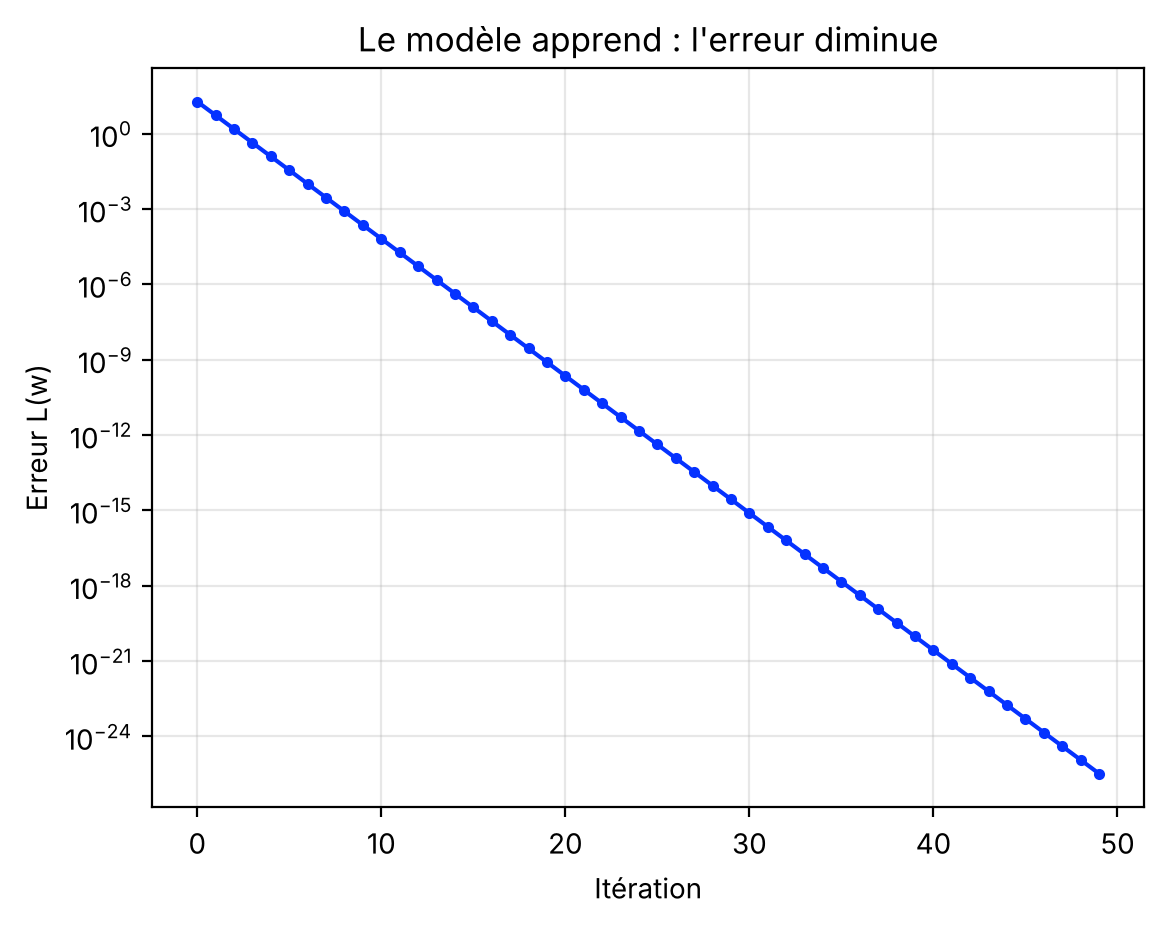

In [5]:
plt.plot(historique, "o-", color="#0532FF", markersize=3)
plt.xlabel("Itération"); plt.ylabel("Erreur L(w)"); plt.yscale("log")
plt.title("Le modèle apprend : l'erreur diminue"); plt.grid(alpha=0.3); plt.show()

✅ $w$ converge vers 2 : la règle $y = 2x$ a été **apprise** à partir des données.

## 5. Explorer un jeu de données réel : Iris

In [6]:
iris = load_iris()
df = pd.DataFrame(iris.data, columns=iris.feature_names)
df["espèce"] = iris.target_names[iris.target]
print(df.shape)                        # 150 lignes, 5 colonnes
df.head()

(150, 5)


,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),espèce
0,5.1,3.5,1.4,0.2,setosa
1,4.9,3.0,1.4,0.2,setosa
2,4.7,3.2,1.3,0.2,setosa
3,4.6,3.1,1.5,0.2,setosa
4,5.0,3.6,1.4,0.2,setosa


In [7]:
df.groupby("espèce").mean().round(2)   # moyenne de chaque mesure par espèce

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm)
espèce,,,,
setosa,5.01,3.43,1.46,0.25
versicolor,5.94,2.77,4.26,1.33
virginica,6.59,2.97,5.55,2.03


### 5.1 Visualisation

*Un graphique vaut mieux qu'un long tableau : les espèces se distinguent-elles à l'œil nu ?*

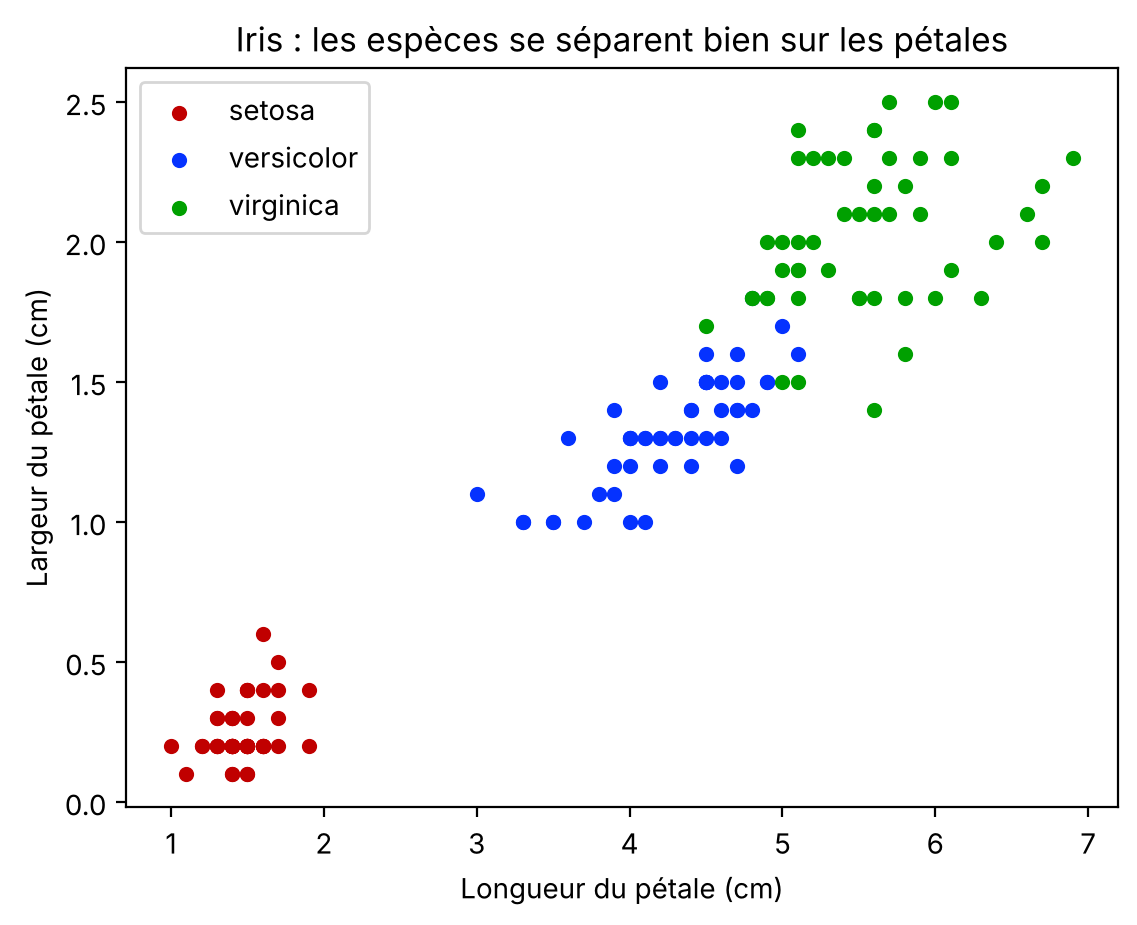

In [8]:
for espece, couleur in zip(iris.target_names, ["#C00000", "#0532FF", "#00A000"]):
    sous = df[df["espèce"] == espece]
    plt.scatter(sous["petal length (cm)"], sous["petal width (cm)"], c=couleur, s=20, label=espece)
plt.xlabel("Longueur du pétale (cm)"); plt.ylabel("Largeur du pétale (cm)")
plt.title("Iris : les espèces se séparent bien sur les pétales"); plt.legend(); plt.show()

## 6. Premier modèle supervisé : KNN

*Le modèle saura-t-il reconnaître des fleurs qu'il n'a jamais vues ?*

On sépare les données : 70 % pour apprendre, 30 % pour tester sur des fleurs **jamais vues**.

In [9]:
X_train, X_test, y_train, y_test = train_test_split(
    iris.data, iris.target, test_size=0.3, random_state=42, stratify=iris.target)
modele = KNeighborsClassifier(n_neighbors=5)
modele.fit(X_train, y_train)                   # apprentissage
y_pred = modele.predict(X_test)                # prédiction sur le test
print("Exactitude sur le test :", round(accuracy_score(y_test, y_pred), 3))

Exactitude sur le test : 0.978


### 6.1 Évaluation : apprentissage contre test

*Un score parfait à l'entraînement, est-ce vraiment une bonne nouvelle ?*

In [10]:
for k in [1, 5, 50]:
    m = KNeighborsClassifier(n_neighbors=k).fit(X_train, y_train)
    print(f"k = {k:2d} : exactitude apprentissage = {m.score(X_train, y_train):.3f}   test = {m.score(X_test, y_test):.3f}")

k =  1 : exactitude apprentissage = 1.000   test = 0.933
k =  5 : exactitude apprentissage = 0.971   test = 0.978
k = 50 : exactitude apprentissage = 0.895   test = 0.889


Avec $k = 1$, le modèle a 100 % sur l'apprentissage (il « apprend par cœur ») : ce chiffre ne dit rien sur sa capacité à **généraliser**. Seul le score de test compte.

## 7. Premier modèle non supervisé : K-means

*Et sans étiquette, la machine peut-elle retrouver les espèces seule ?*

On oublie les espèces et on demande à K-means de trouver 3 groupes.

In [11]:
kmeans = KMeans(n_clusters=3, n_init=10, random_state=42)
groupes = kmeans.fit_predict(iris.data)        # aucune étiquette utilisée
pd.crosstab(groupes, df["espèce"], rownames=["groupe trouvé"], colnames=["vraie espèce"])

vraie espèce,setosa,versicolor,virginica
groupe trouvé,,,
0,0,48,14
1,50,0,0
2,0,2,36


K-means retrouve presque les espèces sans jamais les avoir vues. *Setosa* est parfaitement isolée.

### 7.1 Influence d'un hyperparamètre : le pas d'apprentissage α

*Que se passe-t-il si l'on apprend trop lentement… ou trop vite ?*

In [12]:
for alpha_test in [0.01, 0.05, 0.2, 0.25]:
    w_test = 0.0
    for _ in range(20):
        w_test = w_test - alpha_test * 2 * np.mean((w_test * x - y) * x)
    print(f"α = {alpha_test} : w après 20 itérations = {w_test:.3f}")

α = 0.01 : w après 20 itérations = 1.718
α = 0.05 : w après 20 itérations = 2.000
α = 0.2 : w après 20 itérations = 1.886
α = 0.25 : w après 20 itérations = -628.674


α = 0.01 est trop lent ; α = 0.05 est un bon choix ; avec α = 0.2, $w$ dépasse la cible à chaque pas et **oscille** autour de 2 ; avec α = 0.25, les oscillations grandissent : l'algorithme **diverge**.

## 8. Exercices

*À vous de jouer ! Les exercices sont classés du plus simple au plus exigeant. Essayez de les faire sans regarder les solutions.*

### Exercice 1 (facile) — Un modèle avec biais
Modifiez la boucle pour apprendre $\hat y = w x + b$ sur $x = (1, 2, 3)$ et $y = (3, 5, 7)$. Quelles valeurs de $w$ et $b$ obtenez-vous ?

In [13]:
# À compléter

### Exercice 2 (moyen) — Statistiques avec pandas
Pour chaque espèce d'Iris, calculez le minimum, le maximum et l'écart-type de la longueur du sépale. Tracez un histogramme de cette variable par espèce.

In [14]:
# À compléter

### Exercice 3 (défi) — Taille de l'ensemble d'apprentissage
Entraînez KNN (k = 5) avec 10 %, 30 %, 50 %, 70 % et 90 % des données pour l'apprentissage (le reste pour le test). Tracez l'exactitude de test en fonction de la taille de l'apprentissage. Que concluez-vous sur l'importance des données ?

In [15]:
# À compléter

## 9. Solutions

*Comparez vos réponses avec les propositions ci-dessous ; il existe souvent plusieurs façons correctes de faire.*

<details>
<summary><b>Solution de l'exercice 1</b> (cliquer pour afficher)</summary>

```python
x1, y1 = np.array([1, 2, 3.]), np.array([3, 5, 7.])
w, b = 0.0, 0.0
for _ in range(2000):
    erreur = w * x1 + b - y1
    w -= 0.05 * 2 * np.mean(erreur * x1)
    b -= 0.05 * 2 * np.mean(erreur)
print(round(w, 3), round(b, 3))      # 2.0  1.0
```
</details>

<details>
<summary><b>Solution de l'exercice 2</b> (cliquer pour afficher)</summary>

```python
print(df.groupby("espèce")["sepal length (cm)"].agg(["min", "max", "std"]).round(2))
for espece in iris.target_names:
    plt.hist(df[df["espèce"] == espece]["sepal length (cm)"], alpha=0.5, label=espece)
plt.legend(); plt.xlabel("Longueur du sépale (cm)"); plt.show()
```
</details>

<details>
<summary><b>Solution de l'exercice 3</b> (cliquer pour afficher)</summary>

```python
tailles = [0.1, 0.3, 0.5, 0.7, 0.9]
scores = []
for t in tailles:
    Xa, Xt, ya, yt = train_test_split(iris.data, iris.target, train_size=t, random_state=42, stratify=iris.target)
    scores.append(KNeighborsClassifier(5).fit(Xa, ya).score(Xt, yt))
plt.plot(tailles, scores, "o-"); plt.xlabel("Part des données pour l'apprentissage"); plt.ylabel("Exactitude test"); plt.show()
```
Avec très peu de données, le modèle généralise moins bien : la quantité de données compte.
</details>

## 10. Conclusion — ce qu'il faut retenir

*Avant de passer à la suite, prenons une minute pour résumer l'essentiel.*

- Un algorithme d'apprentissage = **données + modèle + fonction coût + optimisation**.
- Le modèle **apprend de ses erreurs** : l'erreur diminue à chaque itération.
- **Supervisé** (KNN, avec étiquettes) et **non supervisé** (K-means, sans étiquettes).
- On juge un modèle sur des **données de test**, jamais sur celles d'apprentissage.

➡️ Prochain cours : la validation et l'évaluation des modèles.